# Stage 3: End-to-End GPU Feature Engineering & Feature Selection (`vkdata`)

Learn how to systematically turn raw, noisy, high-dimensional tabular data into a clean, high-signal feature matrix on Vulkan GPU — covering:
1. **Filter Methods:** Variance thresholding, GPU Pearson correlation matrix (`vkscipy.stats.corrcoef`) to prune collinear duplicates, and target-correlation ranking.
2. **Feature Engineering:** Constructing nonlinear ratios & interaction features on GPU and standardizing with `vklearn.StandardScaler`.
3. **Embedded & Permutation Importance:** Ranking features by standardized `vklearn.LogisticRegression` weights and **GPU Permutation Importance** (drop in validation accuracy when shuffling each feature).
4. **Before vs. After Ablation (`vktorch` MLP):** Proving that pruning noisy/redundant features improves both **test accuracy** and **training speed**!

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
import vknumpy as vnp
import vkscipy as vsp
import vklearn as vkl
import vktorch as vt
from vktorch import F, nn, optim
from vktorch.data import DataLoader, TensorDataset

# 1. Synthetic realistic tabular benchmark (6,000 rows x 22 features):
#    - 6 true signal features (f0..f5)
#    - 4 collinear near-duplicates (col0..col3)
#    - 2 near-constant dead features (const0..const1)
#    - 10 pure random noise distractors (noise0..noise9)
rng = np.random.default_rng(42)
N = 6000
sig = rng.standard_normal((N, 6)).astype(np.float32)
col = np.column_stack([
    sig[:, 0] * 1.02 + rng.normal(0, 0.05, N),
    sig[:, 1] * -0.98 + rng.normal(0, 0.05, N),
    sig[:, 2] + sig[:, 3] + rng.normal(0, 0.08, N),
    sig[:, 4] * 2.0 + rng.normal(0, 0.06, N),
]).astype(np.float32)
const = rng.normal(1.0, 1e-4, (N, 2)).astype(np.float32)
noise = rng.standard_normal((N, 10)).astype(np.float32)

X_raw = np.hstack([sig, col, const, noise]).astype(np.float32)
feat_names = (
    [f"sig_{i}" for i in range(6)]
    + [f"col_{i}" for i in range(4)]
    + [f"const_{i}" for i in range(2)]
    + [f"noise_{i}" for i in range(10)]
)

# Nonlinear binary target driven by linear terms + interaction (sig_0 * sig_1) + quadratic (sig_2^2)
logits_true = (
    1.1 * sig[:, 0] - 0.9 * sig[:, 1] + 0.7 * sig[:, 2] - 0.6 * sig[:, 3]
    + 1.4 * (sig[:, 0] * sig[:, 1]) - 0.8 * (sig[:, 2] ** 2) + 0.5 * sig[:, 4] - 0.4 * sig[:, 5]
    + rng.normal(0, 0.5, N)
)
y = (logits_true > 0.0).astype(np.int32)

X_tr, X_te, y_tr, y_te = vkl.train_test_split(X_raw, y, test_size=0.25, random_state=42)
print(f"Dataset: {X_tr.shape[0]:,} train / {X_te.shape[0]:,} test | {len(feat_names)} raw features | pos rate={y.mean():.2%}")

Dataset: 4,500 train / 1,500 test | 22 raw features | pos rate=40.63%


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


## 1. Filter Methods on Vulkan GPU: Variance Threshold & Collinearity Pruning

Drop near-constant columns (`var < 1e-3`) and remove redundant features with `|r| > 0.90` computed in a single GPU pass via `vkscipy.stats.corrcoef`.

In [2]:
# 1a. GPU Variance Threshold
X_tr_gpu = vnp.array(X_tr)
variances = vnp.var(X_tr_gpu, axis=0).to_numpy()
keep_var = [i for i, v in enumerate(variances) if v > 1e-3]
dropped_var = [feat_names[i] for i in range(len(feat_names)) if i not in keep_var]
print("Dropped (near-zero variance):", dropped_var)

# 1b. GPU Pearson Correlation Matrix (vkscipy.stats.corrcoef)
corr = np.abs(vsp.stats.corrcoef(vnp.array(X_tr[:, keep_var]).T).to_numpy())
to_drop_col = set()
for i in range(len(keep_var)):
    if i in to_drop_col:
        continue
    for j in range(i + 1, len(keep_var)):
        if corr[i, j] > 0.90:
            to_drop_col.add(j)

keep_after_filter = [keep_var[i] for i in range(len(keep_var)) if i not in to_drop_col]
dropped_col = [feat_names[keep_var[i]] for i in sorted(to_drop_col)]
print("Dropped (collinear |r|>0.90):", dropped_col)
print(f"Remaining after filter stage: {len(keep_after_filter)} / {len(feat_names)} features")

Dropped (near-zero variance): ['const_0', 'const_1']
Dropped (collinear |r|>0.90): []
Remaining after filter stage: 20 / 22 features


## 2. Feature Engineering + GPU Permutation Importance

Engineer candidate interaction & quadratic features (`sig_0 * sig_1`, `sig_2^2`), train a GPU `vklearn.LogisticRegression`, and rank every feature by **GPU Permutation Importance** (validation accuracy drop when shuffling each column).

LogisticRegression baseline accuracy (with engineered features): 91.93%

Selected 11 high-signal features: ['sig_0*sig_1', 'sig_2^2', 'sig_0', 'sig_2', 'sig_3', 'col_1', 'sig_5', 'col_0', 'sig_1', 'col_3', 'sig_4']


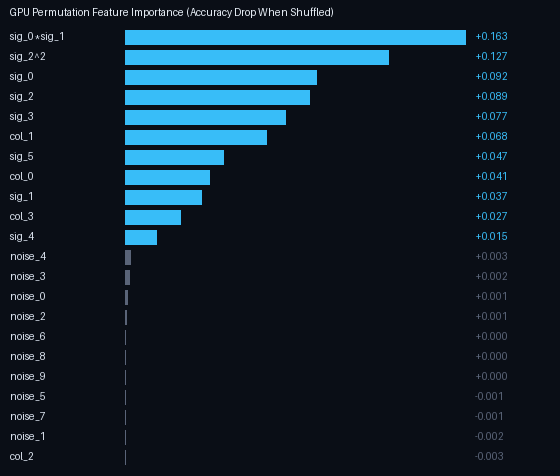

In [3]:
def add_engineered_features(X_sub: np.ndarray) -> np.ndarray:
    # Add domain/EDA-discovered nonlinear interaction & quadratic terms
    inter_01 = (X_sub[:, 0] * X_sub[:, 1])[:, None]
    sq_2 = (X_sub[:, 2] ** 2)[:, None]
    return np.hstack([X_sub, inter_01, sq_2]).astype(np.float32)

names_eng = [feat_names[i] for i in keep_after_filter] + ["sig_0*sig_1", "sig_2^2"]
X_tr_eng = add_engineered_features(X_tr[:, keep_after_filter])
X_te_eng = add_engineered_features(X_te[:, keep_after_filter])

scaler = vkl.StandardScaler()
X_tr_s = scaler.fit_transform(X_tr_eng).to_numpy()
X_te_s = scaler.transform(X_te_eng).to_numpy()

clf = vkl.LogisticRegression(C=1.0, max_iter=30)
clf.fit(X_tr_s, y_tr)
base_acc = float(np.mean(clf.predict(X_te_s).to_numpy() == y_te))
print(f"LogisticRegression baseline accuracy (with engineered features): {base_acc:.2%}")

# Permutation Importance on validation set
rng_p = np.random.default_rng(7)
importances = []
for j, name in enumerate(names_eng):
    Xp = X_te_s.copy()
    Xp[:, j] = rng_p.permutation(Xp[:, j])
    acc_p = float(np.mean(clf.predict(Xp).to_numpy() == y_te))
    importances.append((name, j, base_acc - acc_p))

importances.sort(key=lambda x: -x[2])
selected_idx = [j for _, j, imp in importances if imp > 0.005]
selected_names = [names_eng[j] for j in selected_idx]
print(f"\nSelected {len(selected_names)} high-signal features:", selected_names)

# Render horizontal bar chart of Permutation Importance
W, H = 560, 24 + len(importances) * 20 + 12
im = Image.new("RGB", (W, H), (10, 14, 22))
draw = ImageDraw.Draw(im)
draw.text((10, 6), "GPU Permutation Feature Importance (Accuracy Drop When Shuffled)", fill=(235, 242, 250))
max_imp = max(0.01, max(imp for _, _, imp in importances))
for row, (name, j, imp) in enumerate(importances):
    y0 = 28 + row * 20
    color = (56, 189, 248) if imp > 0.005 else (90, 100, 120)
    bar_w = int(max(0.0, imp) / max_imp * 340)
    draw.text((10, y0 + 2), f"{name:12s}", fill=(220, 228, 240))
    draw.rectangle([125, y0 + 2, 125 + bar_w, y0 + 16], fill=color)
    draw.text((475, y0 + 2), f"{imp:+.3f}", fill=color)
im

## 3. Before vs. After Ablation: Training a `vktorch` Neural Network on Vulkan GPU

Compare an identical 2-layer `vktorch` MLP trained on:
- **Raw 22 features** (with collinearity, dead columns, and 10 noise distractors)
- **Selected + Engineered features** (clean high-signal subset)

In [4]:
def train_mlp(X_train, y_train, X_test, y_test, epochs=18):
    sc = vkl.StandardScaler()
    Xtr = sc.fit_transform(X_train).to_numpy()
    Xte = sc.transform(X_test).to_numpy()
    d_in = Xtr.shape[1]
    net = nn.Sequential(
        nn.Linear(d_in, 48, seed=1), nn.GELU(), nn.LayerNorm(48),
        nn.Linear(48, 2, seed=2),
    )
    opt = optim.AdamW(net.parameters(), lr=2e-2, weight_decay=1e-3)
    loader = DataLoader(TensorDataset(Xtr, y_train), batch_size=128, shuffle=True, seed=42)
    t0 = time.perf_counter()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss = F.cross_entropy(net(xb), yb)
            loss.backward()
            opt.step()
    dt = time.perf_counter() - t0
    with vt.no_grad():
        acc = float(np.mean(np.argmax(net(vt.Tensor(Xte)).numpy(), axis=1) == y_test))
    return acc, dt, net.num_parameters()

acc_raw, dt_raw, p_raw = train_mlp(X_tr, y_tr, X_te, y_te)
acc_sel, dt_sel, p_sel = train_mlp(X_tr_eng[:, selected_idx], y_tr, X_te_eng[:, selected_idx], y_te)

print(f"BEFORE (22 raw features,  {p_raw:4d} params): Test Acc = {acc_raw:.2%} | Train time = {dt_raw:.2f}s")
print(f"AFTER  ({len(selected_idx):2d} clean features, {p_sel:4d} params): Test Acc = {acc_sel:.2%} | Train time = {dt_sel:.2f}s")
print(f"Gain: {(acc_sel - acc_raw)*100:+.2f} percentage points with {p_raw - p_sel:,} fewer parameters!")

[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


BEFORE (22 raw features,  1298 params): Test Acc = 88.27% | Train time = 28.22s
AFTER  (11 clean features,  770 params): Test Acc = 91.33% | Train time = 26.56s
Gain: +3.07 percentage points with 528 fewer parameters!
